In [318]:
#%%
import math
import numpy as np
import inspect
import importlib

import scipy.interpolate

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#parent_directory = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
#sys.path.append(parent_directory)
 
import IoT_node_models 
from IoT_node_models import *

path_to_save_svg = "Saved_Data"



In [319]:

importlib.reload(IoT_node_models)
from IoT_node_models import *

Importing IoT Node models
Importing IoT Node description models
Importing IoT Node hardware models
Importing IoT Node profile models
Importing Wireless communication packages
Importing IoT Node deployment strategies
Importing custom components data


In [320]:
footprintStructure = FootprintStructure(("GWP", "Money"), units=("$kgCO_2 eq.$", "EUR"))

### Data acquisition parameters for MFCC

In [321]:
fs = 16e3

Useful_Samples_p_melvec = 256
Samples_p_melvec        = 1024
N_melvec                = 184

In [322]:

MFCC_aquisition_duration         = Useful_Samples_p_melvec*N_melvec/fs
Audio_classification_p_day       = 0.95*np.floor(24*60*60 / MFCC_aquisition_duration)

print("Acquisition duration  : %.2fms "%((MFCC_aquisition_duration ) *1e3))
print("Inference p day       : %d "%(int(Audio_classification_p_day)))


Acquisition duration  : 2944.00ms 
Inference p day       : 27879 


### Cycles per inference of different literature models

In [323]:
Cycles_p_inference      = (N_melvec*25033 / 0.62) * 0.25 / 0.7482 # Thomas Master thesis
print(Cycles_p_inference)
Cycles_p_inference      = 0.406 * 64e6                            # Tiny-Chirp ML : CNN-Mel @ 64 MHz
print(Cycles_p_inference)
Cycles_p_inference      = 0.210 * 48e6                            # Dongo Net     : CNN-Mel @ 48 MHz
print(Cycles_p_inference)

2482340.4126893794
25984000.0
10080000.0


### Ratio of time for FFT with respect to MFCC in different literature applications

In [324]:

                             #Thomas           #Dongo            # HSP AN6400
FFT_ratio_in_MFCC       =    [0.66*0.9398,      55538/71349,        0.6240]
print(FFT_ratio_in_MFCC)
FFT_ratio_in_MFCC = np.mean(FFT_ratio_in_MFCC)
print("Mean FFT Ratio in MFCC: %.2f"%FFT_ratio_in_MFCC)

[0.620268, 0.7783991366382149, 0.624]
Mean FFT Ratio in MFCC: 0.67


### FFT cycle count in software and in Hardware

In [325]:
FFT_size = 1024
                                      
FFTSW_Cycles            =    (25033*2*N_melvec) # Thomas TFE, based on 25033 cc/512-pt  RFFT
FFTSW_Cycles            =    (55538*  N_melvec) # Dongo     , based on 55538 cc/1024-pt RFFT

Radix = 2**4
FFTHW_Cycles            =    N_melvec*(2*(FFT_size*np.ceil(np.log2(FFT_size)/np.log2(Radix))))/2

### Extraction of cycle for MFCC excluding FFT

In [326]:

Cycles_p_mfcc           =    FFTSW_Cycles / FFT_ratio_in_MFCC
Cycles_p_mfcc_wO_FFT    =    Cycles_p_mfcc - FFTSW_Cycles 

Cycles_total_FFTSW = FFTSW_Cycles+Cycles_p_inference+Cycles_p_mfcc_wO_FFT
Cycles_total_FFTHW = FFTHW_Cycles+Cycles_p_inference+Cycles_p_mfcc_wO_FFT

### Summary of information

In [327]:


print("Cycle for audio classif        : %d"%(int(Cycles_p_mfcc+Cycles_p_inference)))
print("   ->Cycle for inference       : %d"%(int(Cycles_p_inference)))
print("   ->Cycle for MFCC            : %d"%(int(Cycles_p_mfcc)))
print("      ->Cycle for FFTs :   SW  : %d\t(One %i-pt RFFT : %i cc) "%(int(FFTSW_Cycles),FFT_size, int(FFTSW_Cycles/N_melvec)))
print("                           HW  : %d\t(One %i-pt RFFT : %i cc) "%(int(FFTHW_Cycles),FFT_size, int(FFTHW_Cycles/N_melvec)))
print("      ->Cycle for MFCC wO RFFT : %d"%(int(Cycles_p_mfcc_wO_FFT)))
print()

print("")
print("Computation cycles per inference: SW FFT: %d CCs  "%(Cycles_total_FFTSW))
print("Computation cycles per inference: HW FFT: %d CCs  "%(Cycles_total_FFTHW))

Freq_MHz = 32

print("")
print("Computation time @%d MHz per inference: SW FFT: %.2f ms  "%(Freq_MHz, Cycles_total_FFTSW/(Freq_MHz*1e6)*1e3))
print("Computation time @%d MHz per inference: HW FFT: %.2f ms  "%(Freq_MHz, Cycles_total_FFTHW/(Freq_MHz*1e6)*1e3))

print()
print("Acquisition duration     : %.2fms "%((MFCC_aquisition_duration ) *1e3))
print()
print("MFCC acquisition time : %.2fms --- vs --- %.2fms : Calc. time (Full SW)"%(MFCC_aquisition_duration*1e3, 1e3*(Cycles_total_FFTSW)/(1e6*Base_MCU_Clock_freq)))
if MFCC_aquisition_duration<((Cycles_total_FFTSW)/(1e6*Base_MCU_Clock_freq)):
    raise Exception("Melvec acquisition duration is shorter than processing duration!")

Cycle for audio classif        : 25236708
   ->Cycle for inference       : 10080000
   ->Cycle for MFCC            : 15156708
      ->Cycle for FFTs :   SW  : 10218992	(One 1024-pt RFFT : 55538 cc) 
                           HW  : 565248	(One 1024-pt RFFT : 3072 cc) 
      ->Cycle for MFCC wO RFFT : 4937716


Computation cycles per inference: SW FFT: 25236708 CCs  
Computation cycles per inference: HW FFT: 15582964 CCs  

Computation time @32 MHz per inference: SW FFT: 788.65 ms  
Computation time @32 MHz per inference: HW FFT: 486.97 ms  

Acquisition duration     : 2944.00ms 

MFCC acquisition time : 2944.00ms --- vs --- 788.65ms : Calc. time (Full SW)


## Node Description

In [328]:
######################################
#   Avalable MCU choice:
#       - Apollo3 
#       - STM32L4 
#       - nRF52840 
MCU_choice            = "Apollo3"
selected_MCU          = MCU_components[MCU_choice]

######################################
#   Avalable Micro choice:
#       - ICS40310            
#       - DigitalMic          
#       - MP23DB01HP Low Per  
#       - MP23DB01HP          
Micro_choice          = "ICS40310"
selected_Micro        = Micro_components[Micro_choice]

Node_supply = 3.3

print("V_supply is %.1fV, parameters for 3.3V selected "%Node_supply)

V_supply is 3.3V, parameters for 3.3V selected 


In [329]:
active_component_list = [selected_MCU,selected_Micro, radio_component_3V3,bme_component_3V3]

In [330]:

this_LDO = LDO(name = "Node LDO", category = "Power_supply", v_out = 3.3, i_q = 1e-3, v_in = 3.3, component_list = active_component_list)     # XC6206 : 0.228 + Diode and Transistor?

this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 2800, i = 0, selfdischarge_p_year = 5)

this_hw = Hardware(name= "IoT Node",footprintStructure=footprintStructure, categories=DEFAULT_CATEGORIES)
for comp in active_component_list:
    this_hw.add(comp)
this_hw.add(this_LDO)
this_hw.add(this_Batt)

In [331]:

Casing      =this_hw.add(Component(name="Casing", category="Casing",  ))
EoL         =this_hw.add(Component(name="EoL",    category="EoL",     ))
Others      =this_hw.add(Component(name="Others", category="Others",  ))
PCB         =this_hw.add(Component(name="PCB",    category="PCB",     ))
UI          =this_hw.add(Component(name="UI",     category="UI",      ))

### Link the different tasks

In [332]:

Radio_Module   =   radio_component_3V3
Radio_State_TX = radio_state_TX_3V3
Radio_State_RX = radio_state_RX_3V3
Radio_P_TX     =    PTX_PABOOST_3V3 
Radio_I_TX     =      I_PABoost_3V3 
TPHG_Module    =     bme_component_3V3
TPHG_state     = bme_state_TPHG_3V3

In [333]:
MCU_state_active     = selected_MCU  .search_state_name("Active")
Micro_state_active   = selected_Micro.search_state_name("Active")

MCU_state_fftHW   = Digital_Processing_State("512-ptFFT HW",i_per_MHz = (5.5/128), freq_MHz= Base_MCU_Clock_freq)
selected_MCU.add_state(MCU_state_fftHW)


In [334]:
#if v_supply == 1.8 :
#    Radio_Module   =   radio_component_1V8
#    Radio_State_TX = radio_state_TX_1V8
#    Radio_State_RX = radio_state_RX_1V8
#    Radio_P_TX     =    PTX_PABOOST_1V8 
#    Radio_I_TX     =      I_PABoost_1V8 
#    TPHG_Module    =     bme_component_1V8
#    TPHG_state     = bme_state_TPHG_1V8
#    print("V_supply is %.1fV, parameters for 1.8V selected "%v_supply)
#else:
#    Radio_Module   =   radio_component_3V3
#    Radio_State_TX = radio_state_TX_3V3
#    Radio_State_RX = radio_state_RX_3V3
#    Radio_P_TX     =    PTX_PABOOST_3V3 
#    Radio_I_TX     =      I_PABoost_3V3 
#    TPHG_Module    =     bme_component_3V3
#    TPHG_state     = bme_state_TPHG_3V3
#    print("V_supply is %.1fV, parameters for 3.3V selected "%v_supply)

### Create actions of the profile

In [335]:


Audio_classification_w_SWFFT =  Task(  name = "Audio class. w. SW FFT", 
                        actions   = [   Action(                   name='Acquisition',     componentState = Micro_state_active, stateDuration=MFCC_aquisition_duration),
                                        Digital_Processing_Action(name='MFCC w/o FFT'  ,  componentState = MCU_state_active  , cycle_count=Cycles_p_mfcc_wO_FFT),
                                        Digital_Processing_Action(name='Inference'  ,     componentState = MCU_state_active  , cycle_count=Cycles_p_inference),
                                        Digital_Processing_Action(name='SW FFT'  ,        componentState = MCU_state_active  , cycle_count=FFTSW_Cycles)
                        ],
                        taskDuration = MFCC_aquisition_duration, 
                        )

Audio_classification_w_HWFFT =  Task(  name = "Audio class. w. HW FFT", 
                        actions   = [   Action(                   name='Acquisition',     componentState = Micro_state_active, stateDuration=MFCC_aquisition_duration),
                                        Digital_Processing_Action(name='MFCC w/o FFT'  ,  componentState = MCU_state_active  , cycle_count=Cycles_p_mfcc_wO_FFT),
                                        Digital_Processing_Action(name='Inference'  ,     componentState = MCU_state_active  , cycle_count=Cycles_p_inference),
                                        Digital_Processing_Action(name='HW FFT'  ,        componentState = MCU_state_fftHW  ,  cycle_count=FFTHW_Cycles)
                        ],
                        taskDuration = MFCC_aquisition_duration, 
                        )


In [336]:
task_TPHG_sensing   =  Task(  name = "TPHG meas.", 
                        actions   = [   Action(name='Proc',     componentState=MCU_state_active , stateDuration=TPHG_duration+ MCU_BME_duration),
                                        Action(name='TPHG' ,    componentState=TPHG_state       , stateDuration=TPHG_duration)], 
                        taskDuration = TPHG_duration+ MCU_BME_duration)

In [337]:
this_profile= LoRa_Profile("Profile", this_hw,  RX_state=Radio_State_RX,TX_state=Radio_State_TX,
                    P_TX=Radio_P_TX, I_TX=Radio_I_TX ) 
              


In [338]:
Transmission_rate = 24
this_task_tx = this_profile.create_task_tx(name="TX-0", Ptx = 17,SF=12 ,Coding=1,Header=True,DE = 1,BW = 125e3, Payload = 50, TX_rate=Transmission_rate)
this_task_rx = this_profile.create_task_rx(name="RX-0", RX_rate=Transmission_rate, RX_duration=0.250 )

#def PL_model(d):
#    return path_loss(d=d,f = 868e6, n=3)
#    #return path_loss_PLd0(d=d, PLd0=94.40,d0=1, n=2.03)

#this_task_tx.set_Path_loss_model(PL_model)
#this_task_tx.set_distance( d= 1000)


this_profile.add_task(task_TPHG_sensing,task_rate=24*12)

In [339]:
this_profile.add_task(Audio_classification_w_SWFFT ,task_rate=1)
this_profile.add_task(Audio_classification_w_HWFFT ,task_rate=1)

In [340]:
this_profile.change_task_rate(Audio_classification_w_SWFFT      ,Audio_classification_p_day)
this_profile.change_task_rate(Audio_classification_w_HWFFT      ,0)

In [341]:
this_node = Node_description(name="My_node",hardware=this_hw,profile=this_profile)

# Power Analysis

-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     Audio class. w. SW FFTAudio class. w. HW FFTSleep          
Times/day    [1/d]   : 24             24             288            27879.6499999999980              1              
Tot. durat.  [s]     : 55.2468        6.0000         628.7988       82077.6896     0.0000         0.0000         
Tot. en./d   [mJ]    : 18359.0801     223.3440       22983.2152     74681.2011     0.0000         10739.4210     
Node en./d   [mJ]    : 126986.2614     
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3               

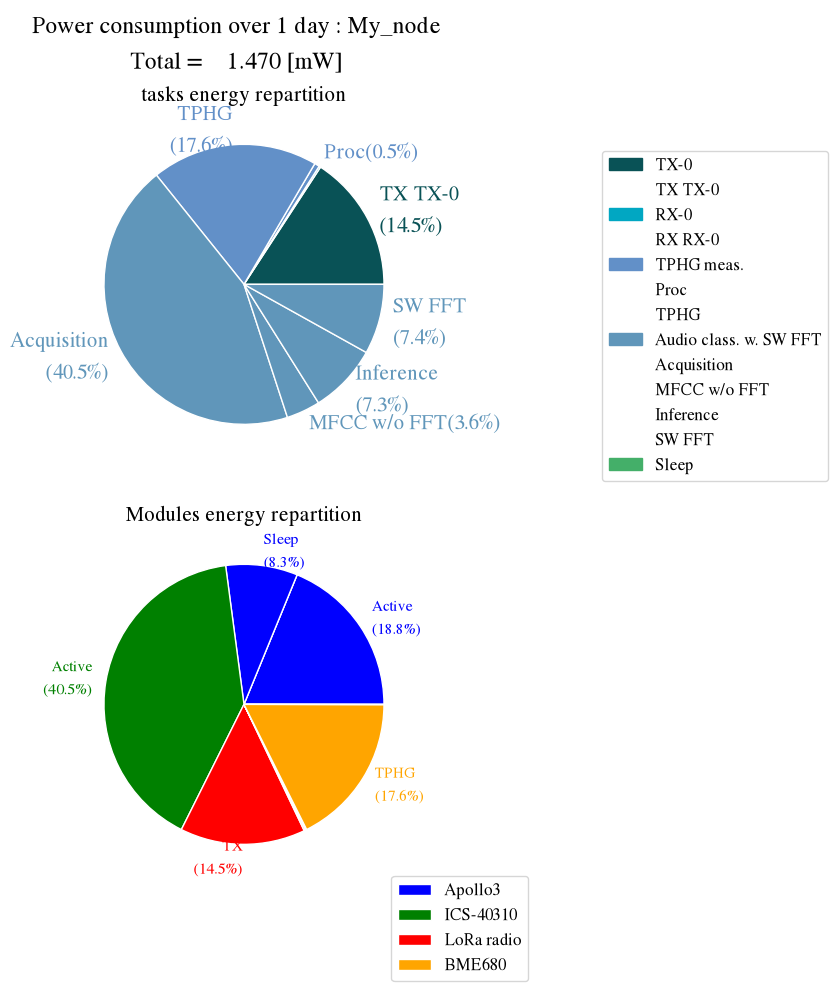

In [342]:
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power(plotAction=True)

In [343]:
this_profile.change_task_rate(Audio_classification_w_HWFFT      ,Audio_classification_p_day)
this_profile.change_task_rate(Audio_classification_w_SWFFT      ,0)

-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     Audio class. w. SW FFTAudio class. w. HW FFTSleep          
Times/day    [1/d]   : 24             24             288            0              27879.6499999999981              
Tot. durat.  [s]     : 55.2468        6.0000         628.7988       0.0000         82077.6896     0.0000         
Tot. en./d   [mJ]    : 18359.0801     223.3440       22983.2152     0.0000         67514.0028     12127.1897     
Node en./d   [mJ]    : 121206.8318     
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3               

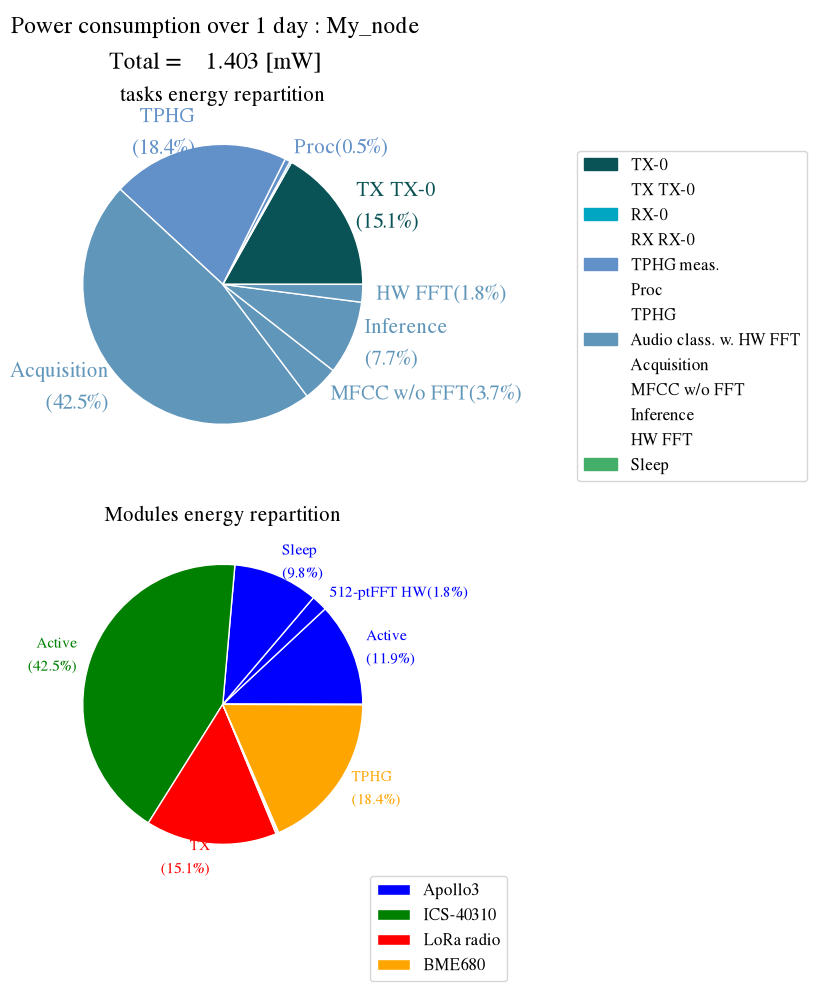

In [344]:
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power(plotAction=True)

# Footprint Analysis

In [345]:

AA_series = 3
AA_footprint = 0.165
AA_cost      = 0.25 
Batt_footprint = AA_series*AA_footprint
Batt_cost      = AA_series*AA_cost


Connectivity = radio_component_3V3
THPG_Sensor  = bme_component_3V3
Power_supply = this_LDO

In [346]:
Casing                  .set_factors(footprintStructure.vector(GWP=(0.3932,   0.709,   1.3259), Money=10))
Connectivity            .set_factors(footprintStructure.vector(GWP=(0.2262,   0.517,   0.5817), Money=5.3))   # SX1276 : 5.3
EoL                     .set_factors(footprintStructure.vector(GWP=(0.0388,   0.0812,  0.1201), Money=0))
Others                  .set_factors(footprintStructure.vector(GWP=(0.0546,   0.0938,  0.1394), Money=1.42))
PCB                     .set_factors(footprintStructure.vector(GWP=(0.9403,   1.17,    1.5696), Money=1.17))
Power_supply            .set_factors(footprintStructure.vector(GWP=(0.0446,   0.132,   0.1751), Money=0.228))
THPG_Sensor             .set_factors(footprintStructure.vector(GWP=(0.0539,   0.0539,  0.5561), Money=6.94)) 
UI                      .set_factors(footprintStructure.vector(GWP=(0.0017,   0.0306, 0.1155), Money=0.54))
this_Batt               .set_factors(footprintStructure.vector(GWP=(Batt_footprint  ,Batt_footprint,Batt_footprint), Money=Batt_cost))


In [315]:
print(MCU_CFemb)
selected_MCU       .set_factors(footprintStructure.vector(GWP=(MCU_CFemb[MCU_choice],    MCU_CFemb[MCU_choice],   MCU_CFemb[MCU_choice]), Money=0))
selected_Micro     .set_factors(footprintStructure.vector(GWP=(MCU_CFemb[MCU_choice],    MCU_CFemb[MCU_choice],   MCU_CFemb[MCU_choice]), Money=0))

{'Apollo3': 0.1160965, 'STM32L4': 0.09206138159999998, 'nRF52840': 0.12410999999999998}


Category      GWP [$kgCO_2 eq.$]       Money [EUR]
------------  -----------------------  -----------
Casing        [0.393, 0.709, 1.33]     10         
Connectivity  [0.226, 0.517, 0.582]    5.3        
EoL           [0.0388, 0.0812, 0.12]   0          
Memory        0                        0          
Others        [0.0546, 0.0938, 0.139]  1.42       
PCB           [0.94, 1.17, 1.57]       1.17       
Power_supply  [0.0446, 0.132, 0.175]   0.228      
Processing    0.09206                  0          
Sensing       [0.146, 0.146, 0.648]    6.94       
UI            [0.0017, 0.0306, 0.116]  0.54       
Battery       0.495                    0.75       
------------  -----------------------  -----------
Total         [2.43, 3.47, 5.26]       26.35      


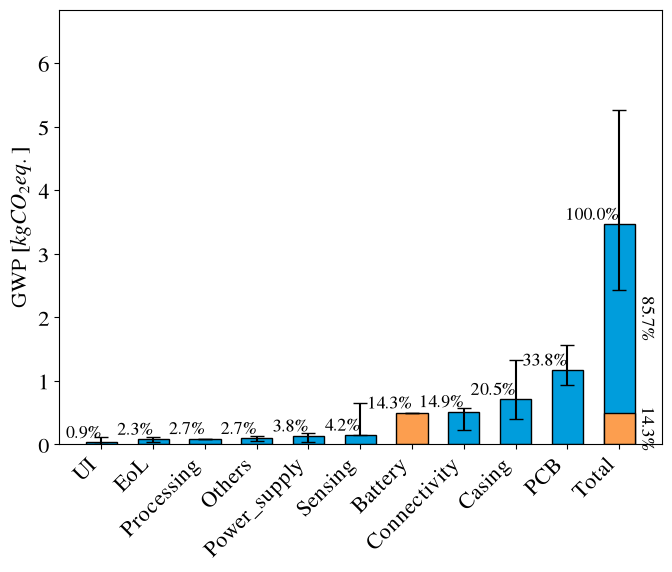

In [314]:

this_hw.compute_footprint()
this_hw.report_footprint()
this_hw.plot_footprint(label="GWP")

In [316]:
Nyears=30

placementNnodes   = 100
decomNnodes       = 100
replacementNnodes = 10

#placementTransport      = Transport(n_node=placementNnodes  , km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")
#decomTransport          = Transport(n_node=decomNnodes      , km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")
#replacementTransport    = Transport(n_node=replacementNnodes, km_fixed=80, km_p_node=1, footprint_p_km=0.350, label="GWP")

placementTransport      = Dum_Transport(n_node=placementNnodes  , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
decomTransport          = Dum_Transport(n_node=decomNnodes      , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
replacementTransport    = Dum_Transport(n_node=replacementNnodes, km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")

deploymentStart = DeploymentStrategy_wTransport( Nyears=Nyears, replacementCategories=None,#("Battery",),
                  transport_placement     =placementTransport, 
                  transport_replacement   =replacementTransport, 
                  transport_decom         =decomTransport,
                  smooth_replacement_footprint = True)

this_node.set_deployment_strategy(deploymentStart)
this_node.compute()

d:\Pol\Documents\Research\Git_Iot_node_modeling\IoT_node_models\Node_description\Node_description.py:328: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


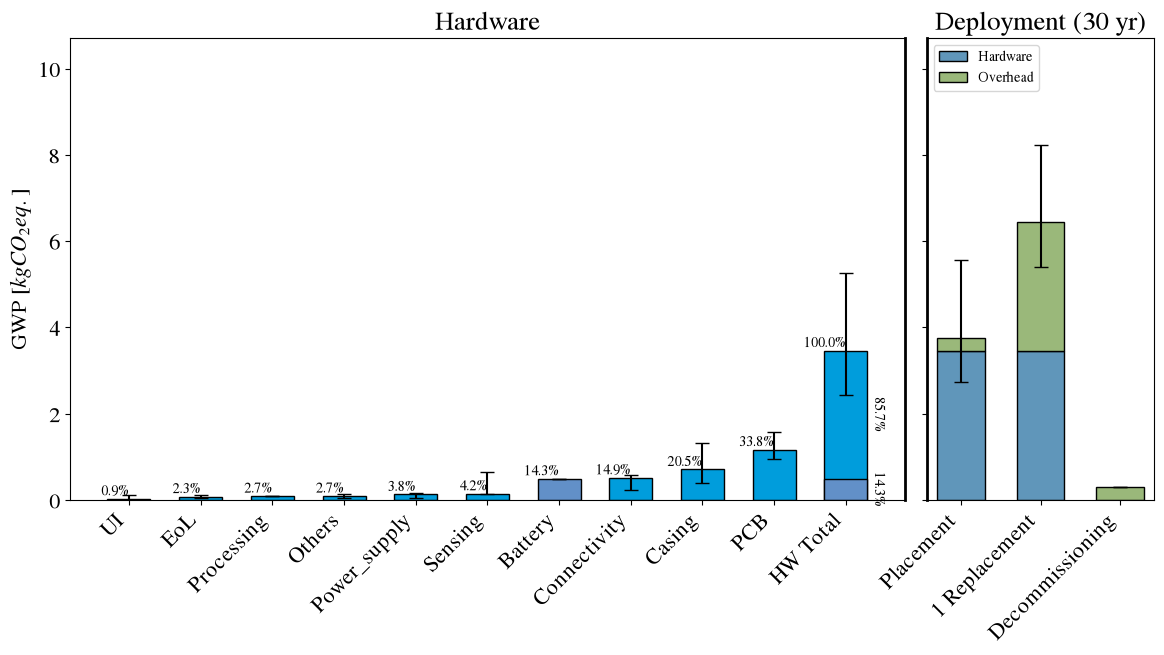

In [317]:
this_node.plot_footprint(label="GWP",cumulated_replacement=False)